This script demonstrates customer segmention ML techniques, as well as anomaly detection.

In [86]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime as dt

from pathlib import Path
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'

# Get data

In [87]:
# Get the raw data here:  
# https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/data?select=HI-Small_accounts.csv
    
# Load engineered AML dataset
# see 00. for CSV build
model_df = pd.read_csv(
    data_dir / 'aml_model_data.csv',
    parse_dates=['Timestamp']
)

# Sort chronologically.
model_df = model_df.sort_values('Timestamp').reset_index(drop=True)

print('Shape:', model_df.shape)
print('\nColumns:')
print(model_df.columns.tolist())

model_df.head()

Shape: (5077237, 20)

Columns:
['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering', 'transaction_date', 'amount_difference', 'amount_difference_pct', 'hour', 'day_of_week', 'is_weekend', 'amount_paid_log', 'amount_received_log', 'same_currency']


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering,transaction_date,amount_difference,amount_difference_pct,hour,day_of_week,is_weekend,amount_paid_log,amount_received_log,same_currency
0,2022-09-01,32282,801B64CE0,32282,801B64CE0,29294.03,US Dollar,29294.03,US Dollar,Reinvestment,0,2022-09-01,0.0,0.0,0,3,0,10.285173,10.285173,1
1,2022-09-01,212818,804B1DF50,212818,804B1DF50,538528.53,Rupee,538528.53,Rupee,Reinvestment,0,2022-09-01,0.0,0.0,0,3,0,13.196598,13.196598,1
2,2022-09-01,16927,8062913A0,28,806291440,96718657.00,Ruble,96718657.00,Ruble,ACH,0,2022-09-01,0.0,0.0,0,3,0,18.387317,18.387317,1
3,2022-09-01,12561,802CF1BB0,18428,8095524B0,2122.85,Euro,2122.85,Euro,Credit Card,0,2022-09-01,0.0,0.0,0,3,0,7.660986,7.660986,1
4,2022-09-01,131086,80CB3F220,131086,80CB3F220,20289185.18,Mexican Peso,20289185.18,Mexican Peso,Reinvestment,0,2022-09-01,0.0,0.0,0,3,0,16.825599,16.825599,1


# Feature engineering
To support customer segmentation, clustering, and behavioral profiling.

In [88]:
# Group transactions by originating customer account.
customer_groups = model_df.groupby('Account')

# Aggregate transaction behavior at the account level.
customer_features = customer_groups.agg(
    transaction_count=('Account', 'size'),

    total_amount_paid=('Amount Paid', 'sum'),
    avg_amount_paid=('Amount Paid', 'mean'),
    median_amount_paid=('Amount Paid', 'median'),
    std_amount_paid=('Amount Paid', 'std'),
    max_amount_paid=('Amount Paid', 'max'),

    avg_amount_received=('Amount Received', 'mean'),
    total_amount_received=('Amount Received', 'sum'),

    avg_amount_difference=('amount_difference', 'mean'),

    avg_transaction_hour=('hour', 'mean'),
    weekend_transaction_rate=('is_weekend', 'mean'),

    unique_recipients=('Account.1', 'nunique'),
    unique_recipient_banks=('To Bank', 'nunique'),

    payment_format_diversity=('Payment Format', 'nunique'),
    currency_diversity=('Payment Currency', 'nunique')
).reset_index()

# Calculate recipient diversity relative to transaction volume.
customer_features['recipient_diversity_rate'] = (
    customer_features['unique_recipients'] /
    customer_features['transaction_count']
)

# Calculate average transactions per active day.
active_days = (
    model_df.groupby('Account')['transaction_date']
    .nunique()
    .reset_index(name='active_days')
)

customer_features = customer_features.merge(
    active_days,
    on='Account',
    how='left'
)

customer_features['transactions_per_active_day'] = (
    customer_features['transaction_count'] /
    customer_features['active_days']
)

# Replace undefined standard deviations for single-transaction accounts.
customer_features['std_amount_paid'] = (
    customer_features['std_amount_paid'].fillna(0)
)

print(f'Customer profiles: {customer_features.shape}')
customer_features.head()

Customer profiles: (496969, 19)


,Account,transaction_count,total_amount_paid,avg_amount_paid,median_amount_paid,std_amount_paid,max_amount_paid,avg_amount_received,total_amount_received,avg_amount_difference,avg_transaction_hour,weekend_transaction_rate,unique_recipients,unique_recipient_banks,payment_format_diversity,currency_diversity,recipient_diversity_rate,active_days,transactions_per_active_day
0,100428660,168672,5.276229e+10,3.128100e+05,1061.850,8.093752e+06,1.615849e+09,3.128100e+05,5.276229e+10,0.0,11.362633,0.132328,14230,618,3,1,0.084365,10,16867.2
1,1004286A8,103018,2.606938e+10,2.530565e+05,856.115,5.877401e+06,8.258079e+08,2.530565e+05,2.606938e+10,0.0,11.346483,0.133171,8846,393,3,1,0.085868,10,10301.8
2,1004286F0,18663,2.465736e+10,1.321189e+06,6280.890,1.980154e+07,1.140426e+09,1.321189e+06,2.465736e+10,0.0,11.393559,0.138724,1575,87,3,1,0.084392,10,1866.3
3,100428738,13756,2.592168e+11,1.884391e+07,110011.380,4.185174e+08,2.984402e+10,1.884391e+07,2.592168e+11,0.0,11.330329,0.133251,1136,42,3,1,0.082582,10,1375.6
4,100428780,17264,3.739337e+11,2.165974e+07,72661.340,4.306818e+08,2.716420e+10,2.165974e+07,3.739337e+11,0.0,11.335438,0.134847,1421,59,3,1,0.082310,10,1726.4


# k-means clustering
Cluster customer financial features to begin building customer profiles.
## Features

In [89]:
from sklearn.preprocessing import StandardScaler

# Select behavioral features for clustering.
clustering_features = [
    'transaction_count',
    'total_amount_paid',
    'avg_amount_paid',
    'median_amount_paid',
    'std_amount_paid',
    'max_amount_paid',
    'avg_amount_received',
    'avg_amount_difference',
    'avg_transaction_hour',
    'weekend_transaction_rate',
    'unique_recipients',
    'unique_recipient_banks',
    'payment_format_diversity',
    'currency_diversity',
    'recipient_diversity_rate',
    'transactions_per_active_day'
]

# Create a separate modeling dataset.
X_cluster = customer_features[clustering_features].copy()

# Apply log transformation to heavily skewed features.
# Why log transformations? Transaction counts and amounts typically have highly right-skewed distributions.
log_features = [
    'transaction_count',
    'total_amount_paid',
    'avg_amount_paid',
    'median_amount_paid',
    'std_amount_paid',
    'max_amount_paid',
    'avg_amount_received',
    'unique_recipients',
    'unique_recipient_banks',
    'transactions_per_active_day'
]

X_cluster[log_features] = np.log1p(X_cluster[log_features])

# Handle any remaining missing or infinite values.
X_cluster = X_cluster.replace([np.inf, -np.inf], np.nan)
X_cluster = X_cluster.fillna(X_cluster.median())

# Standardize features.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print(f'Clustering matrix: {X_scaled.shape}')

Clustering matrix: (496969, 16)


## Determine optimal k
We use two methods to find the optimal number of k=clusters: Elbow and Silhouette Score

In [90]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Evaluate candidate cluster counts.
k_values = range(2, 11)

inertia_scores = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    inertia_scores.append(kmeans.inertia_)

    # Sample customers to keep silhouette calculation manageable.
    silhouette_scores.append(
        silhouette_score(
            X_scaled,
            cluster_labels,
            sample_size=min(10_000, len(X_scaled)),
            random_state=42
        )
    )


- Elbow method: 
Measures how tightly customers are grouped within their clusters (inertia). 
As you increase K, inertia decreases. 
Look for the point where adding more clusters produces diminishing improvements, the "elbow."

- Silhouette score: 
Measures how well-separated the clusters are. 
It considers how close each customer is to its own cluster compared with the nearest neighboring cluster. 
Scores range from -1 to +1. Higher is generally better.

In short: 
Elbow helps determine how many clusters provide sufficient improvement. 
Silhouette helps determine whether those clusters are actually well-defined.



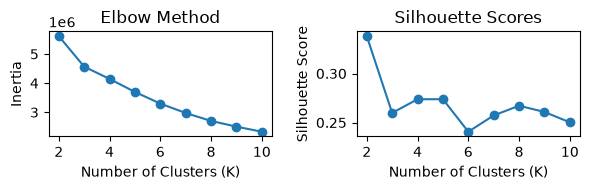

In [91]:
print("""
- Elbow method: 
Measures how tightly customers are grouped within their clusters (inertia). 
As you increase K, inertia decreases. 
Look for the point where adding more clusters produces diminishing improvements, the "elbow."

- Silhouette score: 
Measures how well-separated the clusters are. 
It considers how close each customer is to its own cluster compared with the nearest neighboring cluster. 
Scores range from -1 to +1. Higher is generally better.

In short: 
Elbow helps determine how many clusters provide sufficient improvement. 
Silhouette helps determine whether those clusters are actually well-defined.
""")
    
# Plot evaluation metrics.
fig, axes = plt.subplots(1, 2, figsize=(6, 2))

axes[0].plot(k_values, inertia_scores, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')

axes[1].plot(k_values, silhouette_scores, marker='o')
axes[1].set_title('Silhouette Scores')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

## Fit the cluster model

In [92]:
# Set the selected number of customer segments.
optimal_k = 3 # could try 2,3, or 4

# Initialize and fit the final K-means model.
kmeans_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Assign each customer to a cluster.
customer_features['cluster'] = kmeans_model.fit_predict(X_scaled)

# Examine cluster sizes.
cluster_sizes = (
    customer_features['cluster']
    .value_counts()
    .sort_index()
)

print('Customers per cluster:')
print(cluster_sizes)

# Calculate cluster proportions.
print('\nCustomer distribution:')
print((cluster_sizes / len(customer_features) * 100).round(2))

Customers per cluster:
cluster
0    110525
1    190264
2    196180
Name: count, dtype: int64

Customer distribution:
cluster
0    22.24
1    38.28
2    39.48
Name: count, dtype: float64


## Explore cluster results


What it tells us: 
Whether customers are distributed relatively evenly across clusters or concentrated in a few segments. 
It shows cluster size, not behavioral differences between clusters.

Clusters 1 and 3 account for nearly 77% of customers and are almost identical in size. 
Cluster 2 represents about one-fifth, while Cluster 0 is a small outlier segment.

Key takeaway: 
Cluster 0 deserves closer examination. 
Its small size could reflect a genuinely distinct behavioral group, 
but it could also indicate that K-means isolated unusual customers. 
We need to inspect its feature profile before drawing conclusions.



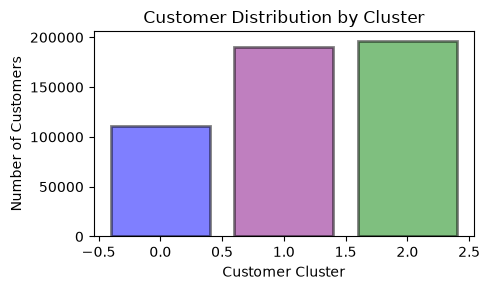

In [93]:
plt.figure(figsize=(5, 3))

plt.bar(
    cluster_sizes.index,
    cluster_sizes.values,
    color=['blue', 'purple','green','yellow'],
    edgecolor='black',
    lw=2,
    alpha=0.5
)

print("""
What it tells us: 
Whether customers are distributed relatively evenly across clusters or concentrated in a few segments. 
It shows cluster size, not behavioral differences between clusters.

Clusters 1 and 3 account for nearly 77% of customers and are almost identical in size. 
Cluster 2 represents about one-fifth, while Cluster 0 is a small outlier segment.

Key takeaway: 
Cluster 0 deserves closer examination. 
Its small size could reflect a genuinely distinct behavioral group, 
but it could also indicate that K-means isolated unusual customers. 
We need to inspect its feature profile before drawing conclusions.
""")

plt.title('Customer Distribution by Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

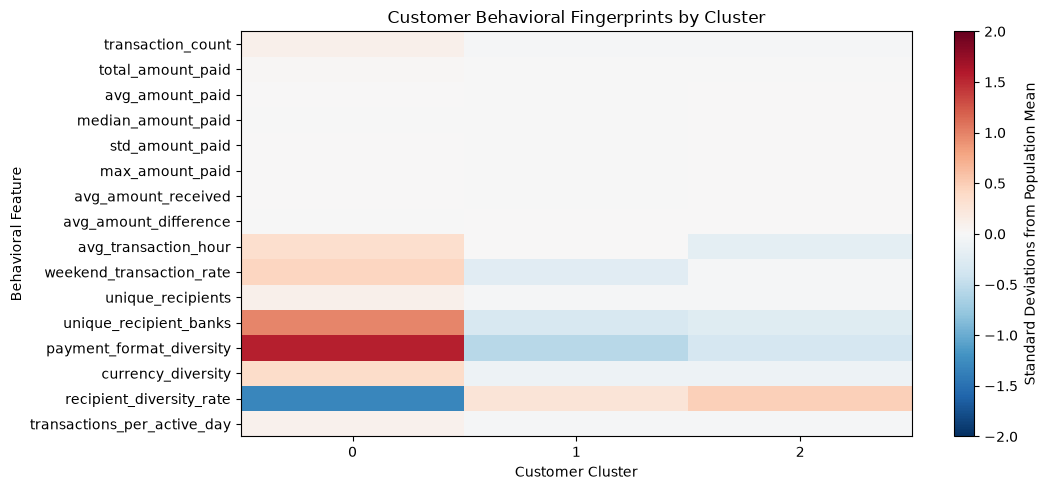

In [94]:
# Calculate average behavior within each cluster.
cluster_means = customer_features.groupby('cluster')[
    clustering_features
].mean()

# Standardize cluster averages against the overall population.
overall_means = customer_features[clustering_features].mean()
overall_stds = customer_features[clustering_features].std()

cluster_profiles = (
    cluster_means - overall_means
) / overall_stds

# Plot the behavioral fingerprints.
fig, ax = plt.subplots(figsize=(11, 5))

im = ax.imshow(
    cluster_profiles.T,
    aspect='auto',
    cmap='RdBu_r',
    vmin=-2,
    vmax=2
)

ax.set_xticks(range(len(cluster_profiles.index)))
ax.set_xticklabels(cluster_profiles.index)
ax.set_yticks(range(len(clustering_features)))
ax.set_yticklabels(clustering_features)

ax.set_title('Customer Behavioral Fingerprints by Cluster')
ax.set_xlabel('Customer Cluster')
ax.set_ylabel('Behavioral Feature')

plt.colorbar(im, ax=ax, label='Standard Deviations from Population Mean')
plt.tight_layout()
plt.show()

In [95]:
print("""
After trying k = 2, 3, and 4, any of the three could be used. 
However, at k = 4, there seems to be more overlap among clusters than at k = 3.

Next steps:
1. Compare K = 2, 3, and 4 using silhouette scores and cluster profiles.
2. Test cluster stability across random seeds.
3. Select the most interpretable, useful segmentation.
4. Build customer-specific behavioral baselines.
5. Detect and explain anomalous transactions.
6. Evaluate detection performance against `Is Laundering` (held out during model development).
""")


After trying k = 2, 3, and 4, any of the three could be used. 
However, at k = 4, there seems to be more overlap among clusters than at k = 3.

Next steps:
1. Compare K = 2, 3, and 4 using silhouette scores and cluster profiles.
2. Test cluster stability across random seeds.
3. Select the most interpretable, useful segmentation.
4. Build customer-specific behavioral baselines.
5. Detect and explain anomalous transactions.
6. Evaluate detection performance against `Is Laundering` (held out during model development).



## Dig deeper into k = 2,3,4

In [96]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Compare candidate cluster counts.
for k in [2, 3, 4]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=10000,
        random_state=42
    )

    print(f'K={k} | Silhouette Score: {score:.4f}')

K=2 | Silhouette Score: 0.3381
K=3 | Silhouette Score: 0.2598
K=4 | Silhouette Score: 0.2738


In [97]:
print("""
What we're looking for: 
Higher silhouette scores indicate better-defined clusters, 
with customers closer to their own cluster than to neighboring clusters.

K=2 has the strongest silhouette score by a meaningful margin.
""")


What we're looking for: 
Higher silhouette scores indicate better-defined clusters, 
with customers closer to their own cluster than to neighboring clusters.

K=2 has the strongest silhouette score by a meaningful margin.



## Fit k=2

In [98]:
# Fit the final two-cluster model.
kmeans_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

customer_features['cluster'] = kmeans_model.fit_predict(X_scaled)

# Compare customer behavior across clusters.
cluster_profile = customer_features.groupby('cluster').agg(
    customer_count=('Account', 'size'),
    avg_transactions=('transaction_count', 'mean'),
    avg_transaction_amount=('avg_amount_paid', 'mean'),
    avg_total_amount=('total_amount_paid', 'mean'),
    avg_unique_recipients=('unique_recipients', 'mean'),
    avg_weekend_rate=('weekend_transaction_rate', 'mean'),
    avg_transactions_per_day=('transactions_per_active_day', 'mean')
).round(2)

print("""
Interpretation
- Cluster 0: Lower-activity accounts with fewer transactions and recipients.
- Cluster 1: Much higher-activity accounts, with substantially greater transaction amounts and recipient diversity.
""")

cluster_profile


Interpretation
- Cluster 0: Lower-activity accounts with fewer transactions and recipients.
- Cluster 1: Much higher-activity accounts, with substantially greater transaction amounts and recipient diversity.



,customer_count,avg_transactions,avg_transaction_amount,avg_total_amount,avg_unique_recipients,avg_weekend_rate,avg_transactions_per_day
cluster,,,,,,,
0,337926,2.22,145505.08,1.503062e+05,1.29,0.03,1.24
1,159043,27.21,16032235.49,1.436438e+08,3.64,0.10,3.68


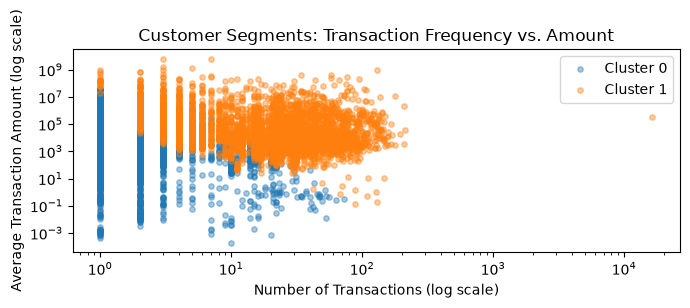

In [99]:
# Sample customers for visualization.
plot_df = customer_features.sample(
    n=min(15000, len(customer_features)),
    random_state=42
)

plt.figure(figsize=(7, 3))

for cluster in sorted(plot_df['cluster'].unique()):
    subset = plot_df[plot_df['cluster'] == cluster]

    plt.scatter(
        subset['transaction_count'],
        subset['avg_amount_paid'],
        label=f'Cluster {cluster}',
        alpha=0.4,
        s=15
    )

plt.xscale('log')
plt.yscale('log')

plt.title('Customer Segments: Transaction Frequency vs. Amount')
plt.xlabel('Number of Transactions (log scale)')
plt.ylabel('Average Transaction Amount (log scale)')
plt.legend()
plt.tight_layout()
plt.show()

In [100]:
print("""
k=2 looks like a good choice.
It produces two distinct groups. 

Interpretation
- Cluster 0: Lower-activity accounts with fewer transactions and recipients.
- Cluster 1: Much higher-activity accounts, with substantially greater transaction amounts and recipient diversity.
""")


k=2 looks like a good choice.
It produces two distinct groups. 

Interpretation
- Cluster 0: Lower-activity accounts with fewer transactions and recipients.
- Cluster 1: Much higher-activity accounts, with substantially greater transaction amounts and recipient diversity.



# Hierarchical clustering
Key distinction:  
K-means directly partitions customers into a predefined number of groups.  
Hierarchical clustering builds a tree of relationships, allowing you to explore different levels of segmentation.

For AML:
K-means is practical for large-scale customer segmentation.  
Hierarchical clustering is useful for exploring relationships and identifying natural groupings in a representative sample.

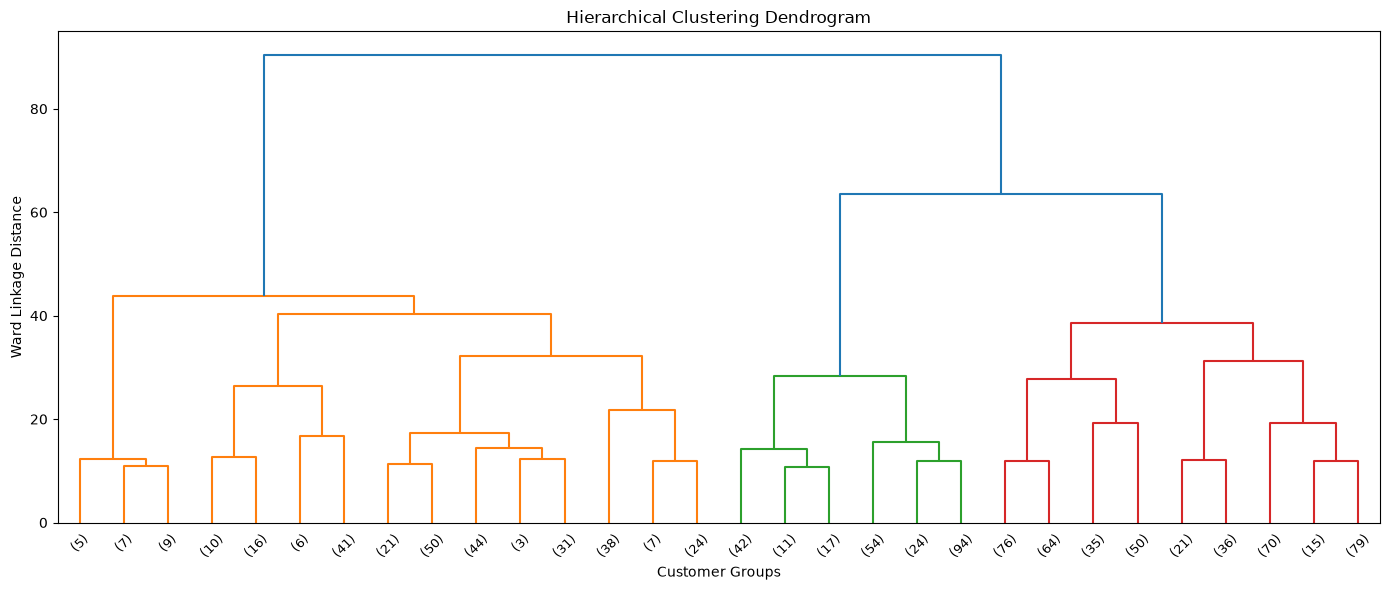

In [101]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Sample customers for hierarchical clustering.
X_sample = X_scaled[
    np.random.RandomState(42).choice(
        len(X_scaled), size=1000, replace=False
    )
]

# Perform hierarchical clustering using Ward's method.
linkage_matrix = linkage(
    X_sample,
    method='ward'
)

# Plot the dendrogram.
plt.figure(figsize=(14, 6))

dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=45,
    leaf_font_size=9
)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Customer Groups')
plt.ylabel('Ward Linkage Distance')
plt.tight_layout()
plt.show()

In [102]:
print("""
Hierarchical clustering is great for detecting unusual customer profiles.
It can identify small, distinct clusters or customers that merge with other groups only at high linkage distances.

Linkage distances:
Ward's method measures the increase in within-cluster variation (sum of squared distances) 
that would result from merging two clusters.

How to interpret it
- Low linkage distance: The clusters being merged contain customers with relatively similar behavior.
- High linkage distance: The clusters being merged are relatively dissimilar.

On the dendrogram, linkage distance is the vertical axis.
""")


Hierarchical clustering is great for detecting unusual customer profiles.
It can identify small, distinct clusters or customers that merge with other groups only at high linkage distances.

Linkage distances:
Ward's method measures the increase in within-cluster variation (sum of squared distances) 
that would result from merging two clusters.

How to interpret it
- Low linkage distance: The clusters being merged contain customers with relatively similar behavior.
- High linkage distance: The clusters being merged are relatively dissimilar.

On the dendrogram, linkage distance is the vertical axis.



# PCA (Principal Component Analysis)
Reduces many features into a few features which explain P% of the variance in the data.

The thinking is, though we may have, say, 100 features, most of the data can be "explained" by three of them, and the other 97 features are redundant or contribute relatively little additional information.

In [103]:
print("""
Recall the X feature columns:
""")
print(list(X_cluster.columns))


Recall the X feature columns:

['transaction_count', 'total_amount_paid', 'avg_amount_paid', 'median_amount_paid', 'std_amount_paid', 'max_amount_paid', 'avg_amount_received', 'avg_amount_difference', 'avg_transaction_hour', 'weekend_transaction_rate', 'unique_recipients', 'unique_recipient_banks', 'payment_format_diversity', 'currency_diversity', 'recipient_diversity_rate', 'transactions_per_active_day']


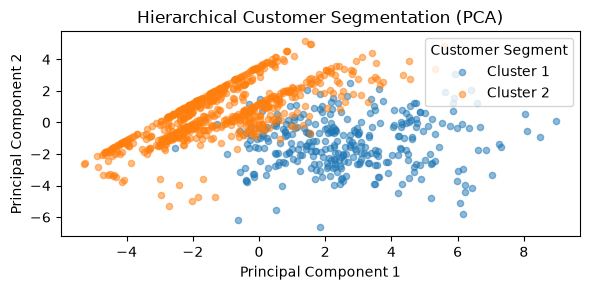

Variance explained: 69.5%

PCA (Principal Component Analysis) reduces many features into fewer dimensions 
while retaining as much variation in the data as possible.



In [104]:
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import fcluster
import matplotlib.pyplot as plt
import pandas as pd

# Assign hierarchical cluster labels.
hierarchical_labels = fcluster(
    linkage_matrix,
    t=2, # <------------------------------------- note, same as k=2 clusters above
    criterion='maxclust'
)

# Reduce the sampled customer features to two dimensions.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_sample)

# Create plotting dataframe.
plot_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'cluster': hierarchical_labels
})

# Plot customer segments.
plt.figure(figsize=(6, 3))

for cluster in sorted(plot_df['cluster'].unique()):
    subset = plot_df[plot_df['cluster'] == cluster]

    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        label=f'Cluster {cluster}',
        alpha=0.5,
        s=20
    )

plt.title('Hierarchical Customer Segmentation (PCA)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Customer Segment')
plt.tight_layout()
plt.show()

print(
    f'Variance explained: {pca.explained_variance_ratio_.sum():.1%}'
)

print("""
PCA (Principal Component Analysis) reduces many features into fewer dimensions 
while retaining as much variation in the data as possible.
""")

## Understand what original features make up each PCA component

In [105]:
# Display feature contributions to each principal component.
pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=clustering_features,
    columns=['PC1', 'PC2']
)

print("""
Inspect the PCA features to understand how they're formed.
"AmountPaid" is a top driving factor.
""")

# Sort features by absolute contribution to each component.
print('PC1 strongest contributors:')
print(pca_loadings['PC1'].abs().sort_values(ascending=False).head())

print('\nPC2 strongest contributors:')
print(pca_loadings['PC2'].abs().sort_values(ascending=False).head())


Inspect the PCA features to understand how they're formed.
"AmountPaid" is a top driving factor.

PC1 strongest contributors:
total_amount_paid           0.347229
std_amount_paid             0.327448
max_amount_paid             0.325887
transaction_count           0.291337
payment_format_diversity    0.287768
Name: PC1, dtype: float64

PC2 strongest contributors:
median_amount_paid     0.426206
avg_amount_paid        0.358282
avg_amount_received    0.358121
transaction_count      0.308104
unique_recipients      0.275586
Name: PC2, dtype: float64


# Anomaly detection
On the Account level.

In [106]:
# Store anomaly detection results.
anomaly_results = []

def evaluate_anomaly_model(scores, predictions, model_name):

    anomaly_results.append({
        'model': model_name,
        'anomaly_count': predictions.sum(),
        'anomaly_rate': predictions.mean(),
        'mean_anomaly_score': scores[predictions].mean(),
        'median_anomaly_score': np.median(scores[predictions])
    })

## Anomaly detection: Baseline model
Use z-scores, the classic "an outlier is a value 3 or more standard deviations from the mean".

In [107]:
# Calculate normal transaction behavior for each account.
account_baselines = model_df.groupby('Account').agg(
    avg_amount=('Amount Paid', 'mean'),
    std_amount=('Amount Paid', 'std'),
    avg_frequency=('Timestamp', 'count')
).reset_index()

account_baselines['std_amount'] = (
    account_baselines['std_amount'].fillna(0)
)

# Attach customer-specific baselines to individual transactions.
anomaly_df = model_df.merge(
    account_baselines,
    on='Account',
    how='left'
)

# Calculate how many standard deviations each transaction
# is from its account's average transaction amount.
anomaly_df['amount_zscore'] = (
    anomaly_df['Amount Paid'] - anomaly_df['avg_amount']
) / anomaly_df['std_amount'].replace(0, np.nan)

# Identify transactions more than three standard deviations
# above the account's average.
anomaly_df['is_anomaly'] = (
    anomaly_df['amount_zscore'] > 3
)

print(anomaly_df['is_anomaly'].value_counts())

# Convert Z-scores into anomaly severity scores.
zscore_scores = anomaly_df['amount_zscore'].abs().fillna(0).to_numpy()

# Store the Z-score results.
evaluate_anomaly_model(
    scores=zscore_scores,
    predictions=anomaly_df['is_anomaly'].to_numpy(),
    model_name='Customer Z-Score'
)

is_anomaly
False    4995074
True       82163
Name: count, dtype: int64


## Anomaly detection: Isolation forest
An unsupervised ML anomaly-detection algorithm that identifies observations that are different from the majority.

It works by randomly splitting features and measuring how many splits it takes to isolate each observation.
- Fewer splits: Easier to isolate, suggesting an anomaly.
- More splits: Harder to isolate, suggesting normal behavior.

In [108]:
from sklearn.ensemble import IsolationForest

# Select transaction-level behavioral features.
anomaly_features = [
    'amount_paid_log',
    'amount_received_log',
    'amount_difference_pct',
    'hour',
    'day_of_week',
    'is_weekend',
    'same_currency'
]

X_anomaly = anomaly_df[anomaly_features].copy()

# Replace infinite values and missing observations.
X_anomaly = X_anomaly.replace([np.inf, -np.inf], np.nan)
X_anomaly = X_anomaly.fillna(X_anomaly.median())

In [109]:
# Fit an Isolation Forest anomaly detection model.
isolation_model = IsolationForest(
    n_estimators=100,
    contamination='auto',
    random_state=42,
    n_jobs=-1
)

isolation_model.fit(X_anomaly)

# Generate anomaly predictions.
# Isolation Forest returns -1 for anomalies and 1 for normal observations.
isolation_predictions = isolation_model.predict(X_anomaly)

# Convert predictions to binary anomaly flags.
isolation_anomalies = (isolation_predictions == -1)

# Generate anomaly severity scores (higher = more anomalous).
isolation_scores = -isolation_model.score_samples(X_anomaly)

# Record results.
evaluate_anomaly_model(
    scores=isolation_scores,
    predictions=isolation_anomalies,
    model_name='Isolation Forest'
)

In [110]:
print("""
Next steps:
Train the hyperparamters and choose best performing model.
""")


Next steps:
Train the hyperparamters and choose best performing model.



## Anomaly detection: Local Outlier Factor (LOF)
Closely related to K-nearest neighbors (KNN).
Both identify nearby observations using distance, but they use that information differently:
- KNN: Finds the K nearest observations.
- LOF: Uses the K nearest observations to compare local data density.
If a transaction sits in a much less dense region than its neighbors, LOF assigns it a higher anomaly score.

Key distinction: KNN measures proximity; LOF measures relative local density.

In [111]:
# Sample transactions for faster LOF experimentation.
X_lof = X_anomaly.sample(
    n=50_000,
    random_state=42
)

neighbor_values = [x*5 for x in [10, 20, 40, 60]]
lof_results = []

for i, n in enumerate(neighbor_values, start=1):

    print(f'Running LOF {i}/{len(neighbor_values)}: n_neighbors={n}')

    model = LocalOutlierFactor(
        n_neighbors=n,
        contamination='auto',
        n_jobs=-1
    )

    predictions = model.fit_predict(X_lof)
    scores = -model.negative_outlier_factor_

    lof_results.append({
        'n_neighbors': n,
        'anomaly_count': (predictions == -1).sum(),
        'anomaly_rate': (predictions == -1).mean(),
        'mean_anomaly_score': scores[predictions == -1].mean()
    })

    print(f'Completed: {lof_results[-1]["anomaly_count"]:,} anomalies detected')

lof_results_df = pd.DataFrame(lof_results)
lof_results_df

Running LOF 1/4: n_neighbors=50
Completed: 601 anomalies detected
Running LOF 2/4: n_neighbors=100
Completed: 1,141 anomalies detected
Running LOF 3/4: n_neighbors=200
Completed: 1,467 anomalies detected
Running LOF 4/4: n_neighbors=300
Completed: 1,290 anomalies detected


,n_neighbors,anomaly_count,anomaly_rate,mean_anomaly_score
0,50,601,0.01202,5.159360
1,100,1141,0.02282,3.444945
2,200,1467,0.02934,7.232358
3,300,1290,0.02580,22.290844


In [112]:
print("""
To save computation time, this LOF analysis considers only a small subset of data. 
So, beware of these results.

Next steps:
- Parameter stability: Compare anomaly overlap across n_neighbors values.
- Select a parameter: Choose a neighborhood size that produces reasonably stable results.
- Inspect top anomalies: Review the highest LOF-scoring transactions and identify common characteristics.
""")


To save computation time, this LOF analysis considers only a small subset of data. 
So, beware of these results.

Next steps:

Parameter stability: Compare anomaly overlap across n_neighbors values.

Select a parameter: Choose a neighborhood size that produces reasonably stable results.

Inspect top anomalies: Review the highest LOF-scoring transactions and identify common characteristics.



## Anomaly detection: Neural network: Autoencoder
Autoencoder: compresses input features into a smaller representation,
then reconstructs the original input; useful for anomaly detection.

### Autoencoder vs other popular neural networks
LSTM (Long Short-Term Memory): learns sequential patterns over time using memory cells and gates; useful for detecting unusual behavior sequences.

GRU (Gated Recurrent Unit): similar to LSTM but uses a simpler architecture with fewer gates and generally fewer parameters.

CNN (Convolutional Neural Network): uses convolutional filters to identify local patterns in data; useful for detecting recurring patterns in sequences.

Note: These approaches can be combined, such as an LSTM autoencoder for sequential anomaly detection.

### Autoencoder deep-dive + AML use case
What is the advantage of compressing then reconstructing the data?

The advantage is that the autoencoder is forced to learn the underlying relationships and structure in the data rather than simply memorizing every feature independently.

1. Compression: The encoder takes seven transaction features and compresses them into three values. It must learn which combinations of information are important.
2. Reconstruction: The decoder uses those three values to reproduce the original seven features.
3. Error measurement: If a transaction follows familiar patterns, the model should reconstruct it reasonably well. If it has unusual combinations of features, reconstruction may be less accurate.

Why this helps anomaly detection:

Imagine an account typically makes transactions involving moderate amounts, particular payment formats, and certain transaction times.

A transaction involving an unusual combination of those characteristics may not fit the patterns the autoencoder learned, producing a higher reconstruction error.

The key advantage is that it can detect multivariate anomalies: transactions that might look normal when examining each feature individually but are unusual when considering the features together.

That's what makes it interesting for AML.

### Autoencoder: Prep

In [56]:
from sklearn.preprocessing import StandardScaler
import torch # PyTorch is an open-source machine learning and deep learning framework
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# sort transactions chronologically
X_auto = anomaly_df.sort_values('Timestamp').copy()

# reserve the final 20% of transactions for validation
split_idx = int(len(X_auto) * 0.80)

X_train = X_auto[anomaly_features].iloc[:split_idx].copy()
X_val = X_auto[anomaly_features].iloc[split_idx:].copy()

# standardize using training data only
auto_scaler = StandardScaler()

X_train_scaled = auto_scaler.fit_transform(X_train)
X_val_scaled = auto_scaler.transform(X_val)

# convert to pytorch tensors
# A torch.Tensor is the fundamental, multi-dimensional data structure in PyTorch used to store
# and manipulate numerical data.
# Functionally, it is highly similar to NumPy's ndarray 
X_train_tensor = torch.FloatTensor(X_train_scaled)
X_val_tensor = torch.FloatTensor(X_val_scaled)

# create data loaders
train_loader = DataLoader(
    TensorDataset(X_train_tensor),
    batch_size=1024,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_tensor),
    batch_size=1024,
    shuffle=False
)

### Autoencoder: Define the model

In [67]:
# define the autoencoder architecture
class Autoencoder(nn.Module):

    def __init__(self, input_dim):
        super().__init__()

        # encode transaction patterns by progressively reducing dimensions
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 16),  # input features to 16 hidden neurons
            nn.ReLU(),                 # introduce nonlinearity
            nn.Linear(16, 8),           # reduce to 8 hidden neurons
            nn.ReLU(),                 # introduce nonlinearity
            nn.Linear(8, 5)             # compress into 5-neuron bottleneck
        )

        # reconstruct the original transaction features from the bottleneck
        self.decoder = nn.Sequential(
            nn.Linear(5, 8),            # expand from 5 to 8 neurons
            nn.ReLU(),                  # introduce nonlinearity
            nn.Linear(8, 16),            # expand to 16 hidden neurons
            nn.ReLU(),                  # introduce nonlinearity
            nn.Linear(16, input_dim)     # reconstruct the original input features
        )

    def forward(self, x):
        # pass input through encoder to create compressed representation
        encoded = self.encoder(x)

        # pass compressed representation through decoder
        reconstructed = self.decoder(encoded)

        # return reconstructed features for comparison with original input
        return reconstructed


# initialize the model
input_dim = X_train_tensor.shape[1]

autoencoder = Autoencoder(input_dim)

# define loss function and optimizer
criterion = nn.MSELoss()

optimizer = torch.optim.AdamW(
    autoencoder.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

# use available hardware
device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

autoencoder = autoencoder.to(device)

### Autoencoder: Training

In [68]:
# ~10-15 min for epochs=10

# set training limits and early stopping parameters

# note, for this example, use 10, but 50 is better.
# however computational complexity increases quickly

epochs = 10                  # maximum number of training iterations

patience = 5                 # stop after 5 epochs without validation improvement
best_val_loss = float('inf') # track the lowest validation loss achieved
epochs_without_improvement = 0  # count consecutive epochs without improvement

for epoch in range(epochs):

    # training phase
    autoencoder.train()
    train_loss = 0

    for (batch,) in train_loader:
        batch = batch.to(device)

        optimizer.zero_grad()

        reconstructed = autoencoder(batch)
        loss = criterion(reconstructed, batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(batch)

    train_loss /= len(train_loader.dataset)

    # validation phase
    autoencoder.eval()
    val_loss = 0

    with torch.no_grad():
        for (batch,) in val_loader:
            batch = batch.to(device)

            reconstructed = autoencoder(batch)
            loss = criterion(reconstructed, batch)

            val_loss += loss.item() * len(batch)

    val_loss /= len(val_loader.dataset)

    print(
        f'Epoch {epoch + 1}/{epochs} | '
        f'Train Loss: {train_loss:.6f} | '
        f'Val Loss: {val_loss:.6f}'
    )

    # save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = {
            key: value.detach().cpu().clone()
            for key, value in autoencoder.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print('Early stopping triggered.')
        break

# restore best model weights
autoencoder.load_state_dict(best_weights)
autoencoder.to(device)

Epoch 1/10 | Train Loss: 0.203783 | Val Loss: 0.189066
Epoch 2/10 | Train Loss: 0.054666 | Val Loss: 0.068326
Epoch 3/10 | Train Loss: 0.020325 | Val Loss: 0.017513
Epoch 4/10 | Train Loss: 0.010872 | Val Loss: 0.014202
Epoch 5/10 | Train Loss: 0.009888 | Val Loss: 0.002572
Epoch 6/10 | Train Loss: 0.012205 | Val Loss: 0.042695
Epoch 7/10 | Train Loss: 0.010563 | Val Loss: 0.021778
Epoch 8/10 | Train Loss: 0.008518 | Val Loss: 0.013492
Epoch 9/10 | Train Loss: 0.011552 | Val Loss: 0.001613
Epoch 10/10 | Train Loss: 0.005421 | Val Loss: 0.023847


Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=7, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=5, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=5, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=7, bias=True)
  )
)

### Autoencoder: Process results

In [72]:
# calculate training reconstruction errors
autoencoder.eval()
train_errors = []

with torch.no_grad():
    for (batch,) in train_loader:
        batch = batch.to(device)

        # reconstruct transactions
        reconstructed = autoencoder(batch)

        # calculate reconstruction error per transaction
        errors = torch.mean(
            (batch - reconstructed) ** 2,
            dim=1
        )

        train_errors.extend(errors.cpu().numpy())

train_errors = np.array(train_errors)

# establish anomaly threshold using the 99th percentile
anomaly_threshold = np.percentile(train_errors, 99)

# flag validation transactions exceeding the reconstruction threshold
autoencoder_predictions = (
    reconstruction_errors > anomaly_threshold
)

# report anomaly detection results
print(f'Anomaly threshold: {anomaly_threshold:.6f}')
print(f'Anomalies detected: {autoencoder_predictions.sum():,}')
print(f'Anomaly rate: {autoencoder_predictions.mean():.2%}')

Anomaly threshold: 0.013708
Anomalies detected: 10,741
Anomaly rate: 1.06%


### Autoencoder: Evaluate

In [73]:
# evaluate the encoder
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

# retrieve held-out laundering labels
y_true = (
    anomaly_df.sort_values('Timestamp')['Is Laundering']
    .iloc[split_idx:]
    .to_numpy()
)

# calculate evaluation metrics
autoencoder_precision = precision_score(
    y_true, autoencoder_predictions, zero_division=0
)

autoencoder_recall = recall_score(
    y_true, autoencoder_predictions, zero_division=0
)

autoencoder_f1 = f1_score(
    y_true, autoencoder_predictions, zero_division=0
)

autoencoder_pr_auc = average_precision_score(
    y_true, reconstruction_errors
)

autoencoder_roc_auc = roc_auc_score(
    y_true, reconstruction_errors
)

print(f'Precision: {autoencoder_precision:.4f}')
print(f'Recall: {autoencoder_recall:.4f}')
print(f'F1: {autoencoder_f1:.4f}')
print(f'PR-AUC: {autoencoder_pr_auc:.4f}')
print(f'ROC-AUC: {autoencoder_roc_auc:.4f}')

Precision: 0.0000
Recall: 0.0000
F1: 0.0000
PR-AUC: 0.0013
ROC-AUC: 0.5215


In [114]:
# Record results.
evaluate_anomaly_model(
    scores=reconstruction_errors,
    predictions=autoencoder_predictions,
    model_name='Autoencoder'
)

## Anomaly detection: final model comparison

In [121]:
# create and sort model comparison
comparison_df = pd.DataFrame(anomaly_results)

comparison_df = comparison_df.sort_values(
    'anomaly_rate',
    ascending=True
).reset_index(drop=True)

# display results
display(comparison_df)

print(
    f"Lowest anomaly rate: "
    f"{comparison_df.iloc[0]['model']}"
)

print("""
- model: Anomaly detection method used.
- anomaly_count: Number of transactions flagged as anomalous.
- anomaly_rate: Percentage of transactions flagged as anomalous.
- mean_anomaly_score: Average anomaly score among flagged transactions; comes from scores[predictions].mean()
- median_anomaly_score: Middle anomaly score among flagged transactions, less influenced by extreme values than the mean.
Important: Anomaly scores are calculated differently by each method, so don't compare their raw magnitudes across models.
""")

,model,anomaly_count,anomaly_rate,mean_anomaly_score,median_anomaly_score
0,Autoencoder,10741,0.010578,0.104951,0.042409
1,Customer Z-Score,82163,0.016183,4.763866,4.280975
2,Isolation Forest,1250618,0.246319,0.563540,0.557587


Lowest anomaly rate: Autoencoder

- model: Anomaly detection method used.
- anomaly_count: Number of transactions flagged as anomalous.
- anomaly_rate: Percentage of transactions flagged as anomalous.
- mean_anomaly_score: Average anomaly score among flagged transactions; comes from scores[predictions].mean()
- median_anomaly_score: Middle anomaly score among flagged transactions, less influenced by extreme values than the mean.
Important: Anomaly scores are calculated differently by each method, so don't compare their raw magnitudes across models.



In [123]:
print("""
Note:
Recall that throughout these examples we used different sample sizes and methods of calculating metrics.
This output is for example only.

In the real world, much more care would have been spent on preparing and staging quality data, 
trying and tuning models, and comparing all models on similar footing.
""")


Note:
Recall that throughout these examples we used different sample sizes and methods of calculating metrics.
This output is for example only.

In the real world, much more care would have been spent on preparing and staging quality data, 
trying and tuning models, and comparing all models on similar footing.



In [124]:
print('done')

done
